<a href="https://colab.research.google.com/github/prettypuela/Customer-Churn-Prediction/blob/main/Nigeria_food_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

In [9]:
import os

os.listdir('/content')


['.config', 'food_data', 'NGA_RTFP_mkt_2007_2026-08-24.zip', 'sample_data']

In [10]:
import os

file_path = '/content/NGA_RTFP_mkt_2007_2026-08-24.zip'

print("File exists:", os.path.exists(file_path))
print("File size:", os.path.getsize(file_path), "bytes")

File exists: True
File size: 4882868 bytes


In [11]:
with zipfile.ZipFile('/content/NGA_RTFP_mkt_2007_2026-08-24.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/food_data')

In [12]:
os.listdir('/content/food_data')

['NGA_RTFP_mkt_2007_2026-08-24.csv']

In [13]:
df = pd.read_csv('/content/food_data/NGA_RTFP_mkt_2007_2026-08-24.csv')

df.head()

,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_yam,c_yam,inflation_yam,trust_yam,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
0,NGA,Nigeria,Abia,Oboma Ngwa,Aba,5.15,7.36,gid_5150000073600000,2007-01-01,2007,...,138.75,147.90,NaN,8.5,0.29,0.30,0.29,0.29,NaN,9.4
1,NGA,Nigeria,Abia,Oboma Ngwa,Aba,5.15,7.36,gid_5150000073600000,2007-02-01,2007,...,141.02,147.78,NaN,8.5,0.30,0.30,0.29,0.30,NaN,9.4
2,NGA,Nigeria,Abia,Oboma Ngwa,Aba,5.15,7.36,gid_5150000073600000,2007-03-01,2007,...,140.38,149.44,NaN,8.5,0.30,0.31,0.29,0.30,NaN,9.4
3,NGA,Nigeria,Abia,Oboma Ngwa,Aba,5.15,7.36,gid_5150000073600000,2007-04-01,2007,...,142.18,152.95,NaN,8.5,0.30,0.31,0.29,0.31,NaN,9.4
4,NGA,Nigeria,Abia,Oboma Ngwa,Aba,5.15,7.36,gid_5150000073600000,2007-05-01,2007,...,145.60,158.16,NaN,8.5,0.31,0.32,0.30,0.31,NaN,9.4


In [14]:
df.shape

(17464, 137)

In [15]:
df.columns

Index(['ISO3', 'country', 'adm1_name', 'adm2_name', 'mkt_name', 'lat', 'lon',
       'geo_id', 'price_date', 'year',
       ...
       'l_yam', 'c_yam', 'inflation_yam', 'trust_yam', 'o_food_price_index',
       'h_food_price_index', 'l_food_price_index', 'c_food_price_index',
       'inflation_food_price_index', 'trust_food_price_index'],
      dtype='object', length=137)

In [16]:
[col for col in df.columns if any(word in col.lower() for word in ['date', 'market', 'rice', 'bean', 'maize', 'gari', 'yam', 'onion'])]

['price_date',
 'beans',
 'gari_fao',
 'maize_fao',
 'maize_flour',
 'onions',
 'rice',
 'rice_fao',
 'yam',
 'o_beans',
 'h_beans',
 'l_beans',
 'c_beans',
 'inflation_beans',
 'trust_beans',
 'o_gari_fao',
 'h_gari_fao',
 'l_gari_fao',
 'c_gari_fao',
 'inflation_gari_fao',
 'trust_gari_fao',
 'o_maize_fao',
 'h_maize_fao',
 'l_maize_fao',
 'c_maize_fao',
 'inflation_maize_fao',
 'trust_maize_fao',
 'o_maize_flour',
 'h_maize_flour',
 'l_maize_flour',
 'c_maize_flour',
 'inflation_maize_flour',
 'trust_maize_flour',
 'o_onions',
 'h_onions',
 'l_onions',
 'c_onions',
 'inflation_onions',
 'trust_onions',
 'o_rice',
 'h_rice',
 'l_rice',
 'c_rice',
 'inflation_rice',
 'trust_rice',
 'o_rice_fao',
 'h_rice_fao',
 'l_rice_fao',
 'c_rice_fao',
 'inflation_rice_fao',
 'trust_rice_fao',
 'o_yam',
 'h_yam',
 'l_yam',
 'c_yam',
 'inflation_yam',
 'trust_yam',
 'o_food_price_index',
 'h_food_price_index',
 'l_food_price_index',
 'c_food_price_index',
 'inflation_food_price_index',
 'trust_food

In [17]:
df.isnull().sum()

,0
ISO3,0
country,0
adm1_name,0
adm2_name,0
mkt_name,0
...,...
h_food_price_index,0
l_food_price_index,0
c_food_price_index,0
inflation_food_price_index,888


In [18]:
df['inflation_food_price_index'].isnull().sum()

np.int64(888)

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.dtypes

,0
ISO3,object
country,object
adm1_name,object
adm2_name,object
mkt_name,object
...,...
h_food_price_index,float64
l_food_price_index,float64
c_food_price_index,float64
inflation_food_price_index,float64


In [21]:
df['price_date'].dtype

dtype('O')

In [22]:
df['price_date'] = pd.to_datetime(df['price_date'])

In [23]:
df['price_date'].dtype

dtype('<M8[ns]')

In [24]:
[col for col in df.columns if 'rice'in col.lower()]

['price_date',
 'rice',
 'rice_fao',
 'o_rice',
 'h_rice',
 'l_rice',
 'c_rice',
 'inflation_rice',
 'trust_rice',
 'o_rice_fao',
 'h_rice_fao',
 'l_rice_fao',
 'c_rice_fao',
 'inflation_rice_fao',
 'trust_rice_fao',
 'o_food_price_index',
 'h_food_price_index',
 'l_food_price_index',
 'c_food_price_index',
 'inflation_food_price_index',
 'trust_food_price_index']

In [25]:
rice_df =df[['price_date','c_rice']].copy()

In [26]:
rice_df['c_rice'].isnull().sum()

np.int64(0)

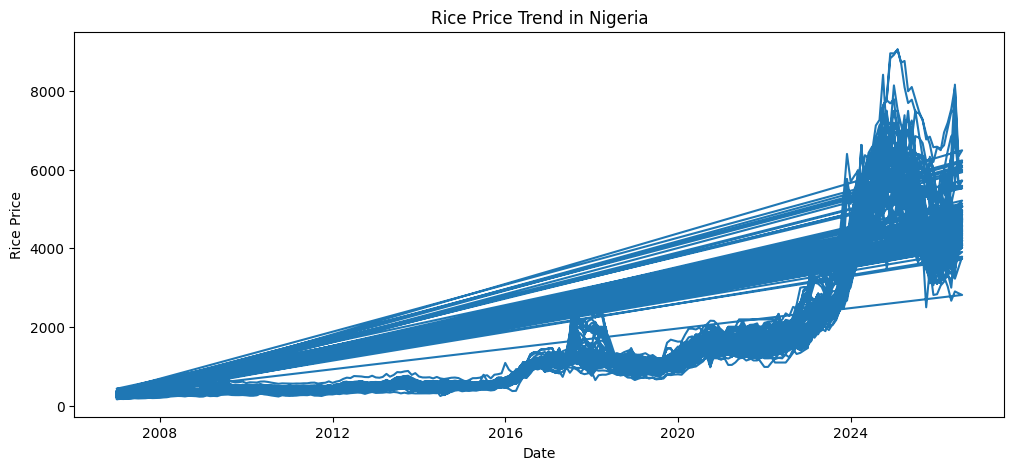

In [27]:
plt.figure(figsize=(12, 5))
plt.plot(rice_df['price_date'], rice_df['c_rice'])
plt.xlabel('Date')
plt.ylabel('Rice Price')
plt.title('Rice Price Trend in Nigeria')
plt.show()

In [28]:
df = pd.read_csv('/content/food_data/NGA_RTFP_mkt_2007_2026-08-24.csv')
df['price_date'] = pd.to_datetime(df['price_date'])

In [29]:
rice_df = df[['price_date', 'c_rice']].copy()

rice_trend = rice_df.groupby('price_date')['c_rice'].mean().reset_index()

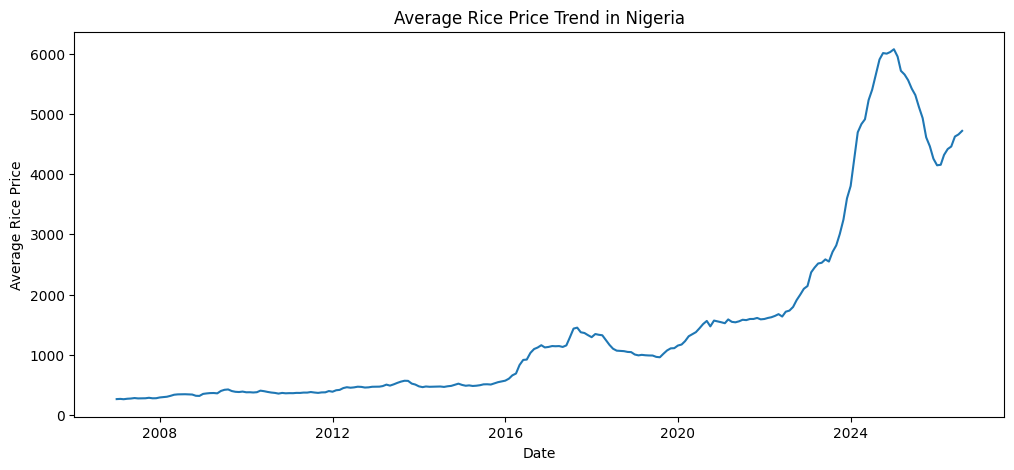

In [30]:
plt.figure(figsize=(12, 5))
plt.plot(rice_trend['price_date'], rice_trend['c_rice'])
plt.xlabel('Date')
plt.ylabel('Average Rice Price')
plt.title('Average Rice Price Trend in Nigeria')
plt.show()

In [31]:
rice_inflation = df[['price_date', 'inflation_rice']].copy()

rice_inflation = rice_inflation.groupby('price_date')['inflation_rice'].mean().reset_index()

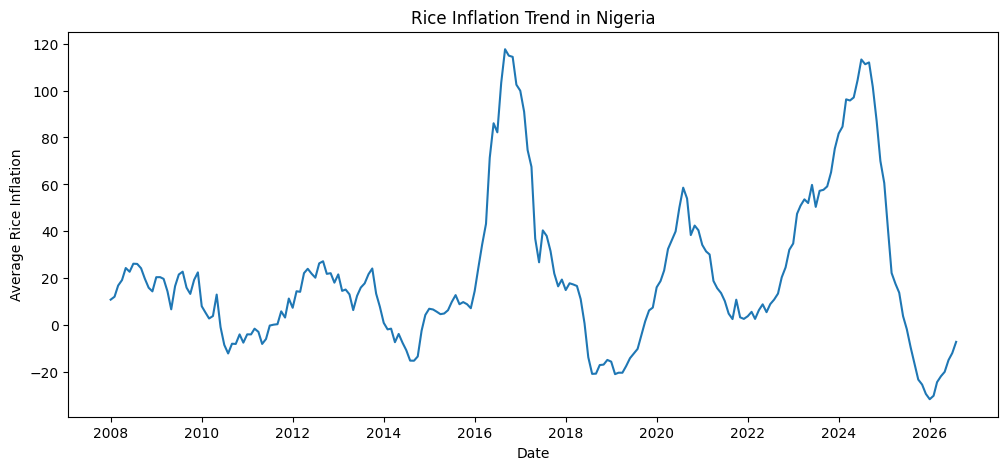

In [32]:
plt.figure(figsize=(12, 5))
plt.plot(rice_inflation['price_date'], rice_inflation['inflation_rice'])
plt.xlabel('Date')
plt.ylabel('Average Rice Inflation')
plt.title('Rice Inflation Trend in Nigeria')
plt.show()

In [33]:
rice_trend['days'] = (rice_trend['price_date'] - rice_trend['price_date'].min()).dt.days

slope, intercept = np.polyfit(rice_trend['days'], rice_trend['c_rice'], 1)

rice_trend['predicted_price'] = intercept + slope * rice_trend['days']

slope, intercept

(np.float64(0.612298670089464), np.float64(-720.3729362427026))

In [34]:
future_dates = pd.date_range(
    start=rice_trend['price_date'].max() + pd.Timedelta(days=30),
    periods=12,
    freq='30D'
)

future_days = (future_dates - rice_trend['price_date'].min()).days

future_prices = intercept + slope * future_days

forecast = pd.DataFrame({
    'price_date': future_dates,
    'forecasted_rice_price': future_prices
})

forecast

,price_date,forecasted_rice_price
0,2026-08-31,3677.156112
1,2026-09-30,3695.525072
2,2026-10-30,3713.894033
3,2026-11-29,3732.262993
4,2026-12-29,3750.631953
5,2027-01-28,3769.000913
6,2027-02-27,3787.369873
7,2027-03-29,3805.738833
8,2027-04-28,3824.107793
9,2027-05-28,3842.476753


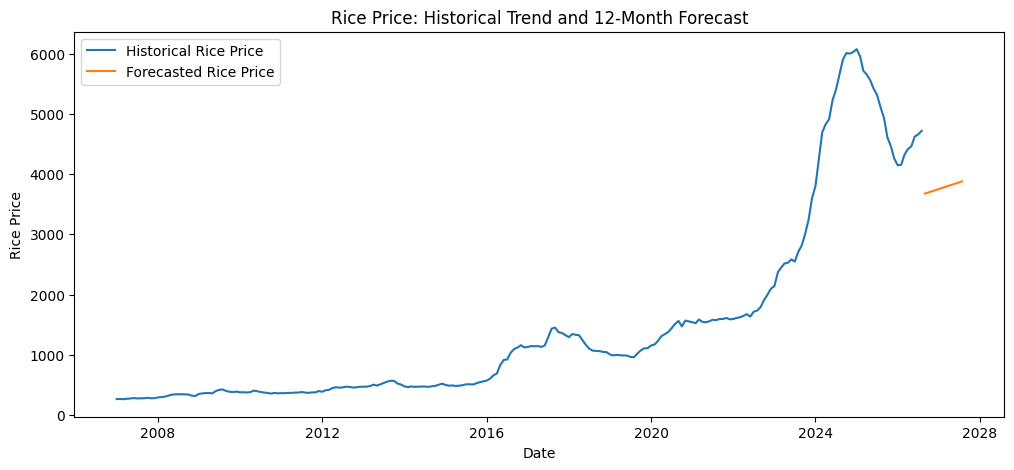

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(
    rice_trend['price_date'],
    rice_trend['c_rice'],
    label='Historical Rice Price'
)

plt.plot(
    forecast['price_date'],
    forecast['forecasted_rice_price'],
    label='Forecasted Rice Price'
)

plt.xlabel('Date')
plt.ylabel('Rice Price')
plt.title('Rice Price: Historical Trend and 12-Month Forecast')
plt.legend()
plt.show()

In [36]:
split_point = int(len(rice_trend) * 0.8)

train = rice_trend.iloc[:split_point].copy()
test = rice_trend.iloc[split_point:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

Training rows: 188
Testing rows: 48


In [37]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

train_days = (
    train['price_date'] - rice_trend['price_date'].min()
).dt.days

test_days = (
    test['price_date'] - rice_trend['price_date'].min()
).dt.days

slope, intercept = np.polyfit(
    train_days, train['c_rice'], 1
)

test_predictions = intercept + slope * test_days

mae = mean_absolute_error(
    test['c_rice'], test_predictions
)

rmse = np.sqrt(mean_squared_error(
    test['c_rice'], test_predictions
))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 2503.4969228083655
RMSE: 2803.2100337082275


In [38]:
comparison = pd.DataFrame({
    'Date': test['price_date'].values,
    'Actual Price': test['c_rice'].values,
    'Predicted Price': test_predictions
})

comparison.head(10)

,Date,Actual Price,Predicted Price
188,2022-09-01,1794.571081,1512.042317
189,2022-10-01,1908.307432,1519.760134
190,2022-11-01,2000.259865,1527.735212
191,2022-12-01,2096.474324,1535.453030
192,2023-01-01,2142.063784,1543.428108
193,2023-02-01,2369.405270,1551.403186
194,2023-03-01,2446.321351,1558.606482
195,2023-04-01,2516.457027,1566.581560
196,2023-05-01,2528.221216,1574.299377
197,2023-06-01,2584.280270,1582.274455


In [39]:
rice_trend['days'] = (
    rice_trend['price_date'] - rice_trend['price_date'].min()
).dt.days

slope, intercept = np.polyfit(
    rice_trend['days'],
    rice_trend['c_rice'],
    1
)

future_dates = pd.date_range(
    start=rice_trend['price_date'].max() + pd.Timedelta(days=30),
    periods=12,
    freq='30D'
)

future_days = (
    future_dates - rice_trend['price_date'].min()
).days

future_prices = intercept + slope * future_days

forecast = pd.DataFrame({
    'price_date': future_dates,
    'forecasted_rice_price': future_prices
})

forecast

,price_date,forecasted_rice_price
0,2026-08-31,3677.156112
1,2026-09-30,3695.525072
2,2026-10-30,3713.894033
3,2026-11-29,3732.262993
4,2026-12-29,3750.631953
5,2027-01-28,3769.000913
6,2027-02-27,3787.369873
7,2027-03-29,3805.738833
8,2027-04-28,3824.107793
9,2027-05-28,3842.476753


In [40]:
print("Number of forecast months:", len(forecast))
print("First forecast date:", forecast['price_date'].min())
print("Last forecast date:", forecast['price_date'].max())

Number of forecast months: 12
First forecast date: 2026-08-31 00:00:00
Last forecast date: 2027-07-27 00:00:00


## Conclusion

This project analyzed historical food prices in Nigeria, with a focus on rice prices. The dataset was inspected and prepared for analysis, and historical rice-price and inflation trends were visualized.

A simple linear trend model was used to forecast rice prices over 12 future periods at 30-day intervals. The model was evaluated using a chronological 80/20 training and testing split.

The evaluation produced a Mean Absolute Error (MAE) of approximately 2,503.50 and a Root Mean Squared Error (RMSE) of approximately 2,803.21. The comparison between actual and predicted prices showed that the model underestimated prices during the displayed test period.

Therefore, the forecast should be interpreted cautiously. The simple linear trend model does not capture all the factors that influence food prices in Nigeria. Future work could explore more advanced forecasting methods and additional economic variables to improve prediction performance.